In [2]:
import base64
import io

import pymupdf
from langchain_core.messages import HumanMessage
from PIL import Image


def image_to_base64_opened(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")

    return base64.b64encode(buffer.getvalue()).decode("utf-8")


def pdf_to_base64_messages(pdf_path: str) -> list[HumanMessage]:
    """將 PDF 所有頁面轉換為 Base64 圖像訊息列表。"""

    #stream（二進位資料）
    #pdf_doc = pymupdf.open(stream=data, filetype="pdf")
    pdf_doc = pymupdf.open(pdf_path)

    messages = []

    for page_number, page in enumerate(pdf_doc):
        pixmap = page.get_pixmap(dpi=200)
        image_bytes = pixmap.tobytes("jpeg")
        image = Image.open(io.BytesIO(image_bytes))
        image_str = image_to_base64_opened(image)
        messages.append(
            HumanMessage(content=[{"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{image_str}"}}]))

    return messages

In [ ]:
with open(image_temp, "rb") as f:
    image.append(f)
    while True:
        try:
            result_edit = await client.images.edit(
                model="gpt-image-2.5-flare",
                image=image,
                prompt=prompt,
                quality=get_model_config(env)['image_quality'],
                size="1792x1008",
            )

In [13]:
from initialization import credential_init

credential_init()


from openai import AsyncOpenAI

client = AsyncOpenAI()

pdf_path = "data/5-3-2 Apply New Samples at EIP - Sample Request 240902 1.pdf"

pdf_doc = pymupdf.open(pdf_path)
results = []

try:
    for page_number, page in enumerate(pdf_doc):

        # 1. PDF 頁面轉 JPEG
        pixmap = page.get_pixmap(
            dpi=200,
            colorspace=pymupdf.csRGB,
            alpha=False,
        )

        image_bytes = pixmap.tobytes("jpeg")

        # 2. 將 Binary 包裝成 OpenAI SDK 可接受的檔案
        image_file = (
            f"page_{page_number + 1}.jpg",
            image_bytes,
            "image/jpeg",
        )

        # 3. 執行 img2img
        result = await client.images.edit(
            model="gpt-image-2.5-sunburst",
            image=image_file,
            prompt="將內容擷取出來，並提升美觀程度",
            quality="medium",
            size="1792x1008",
        )

        # 4. Base64 -> Binary
        image_base64 = result.data[0].b64_json
        output_bytes = base64.b64decode(image_base64)

        results.append(output_bytes)

finally:
    pdf_doc.close()

Page 1


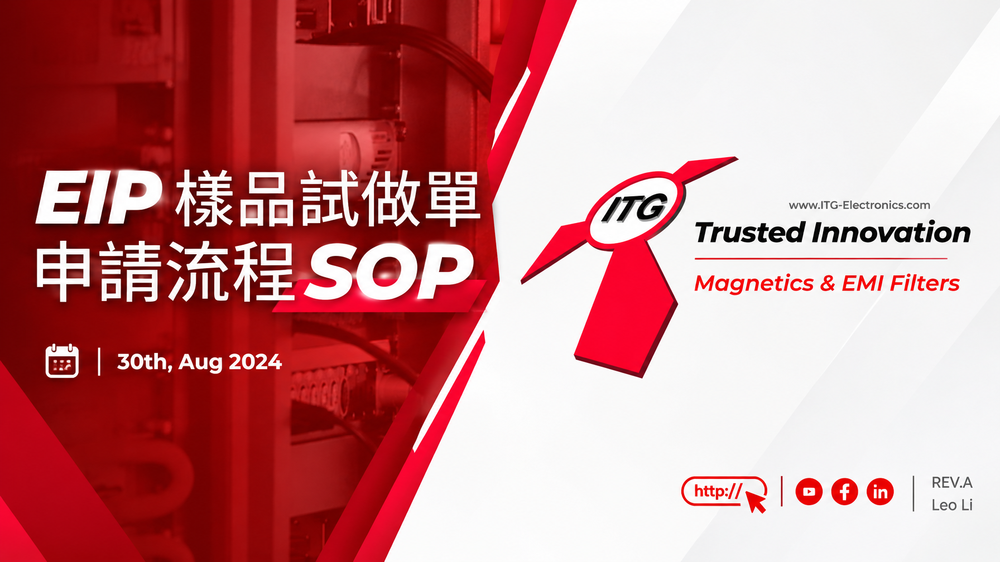

Page 2


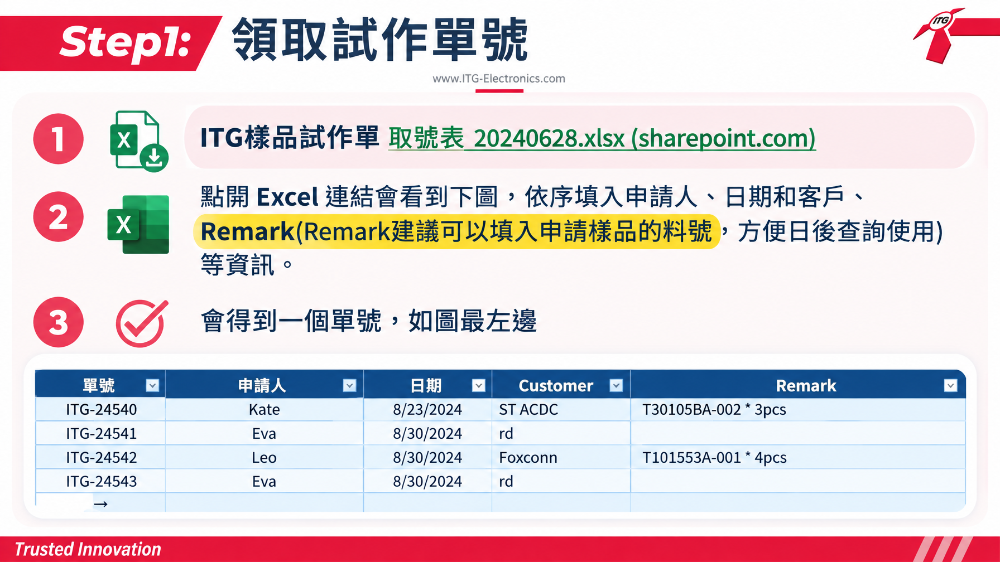

Page 3


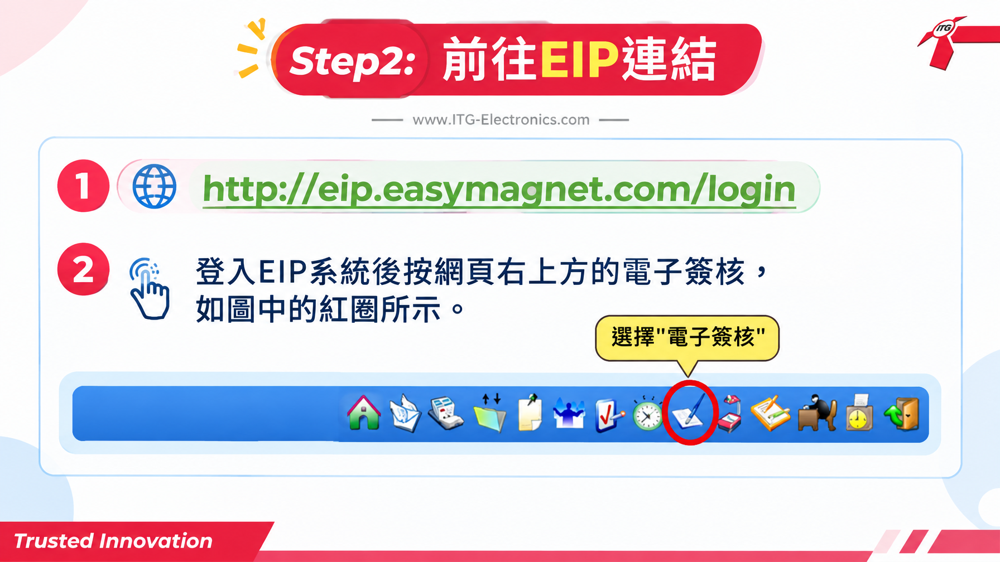

Page 4


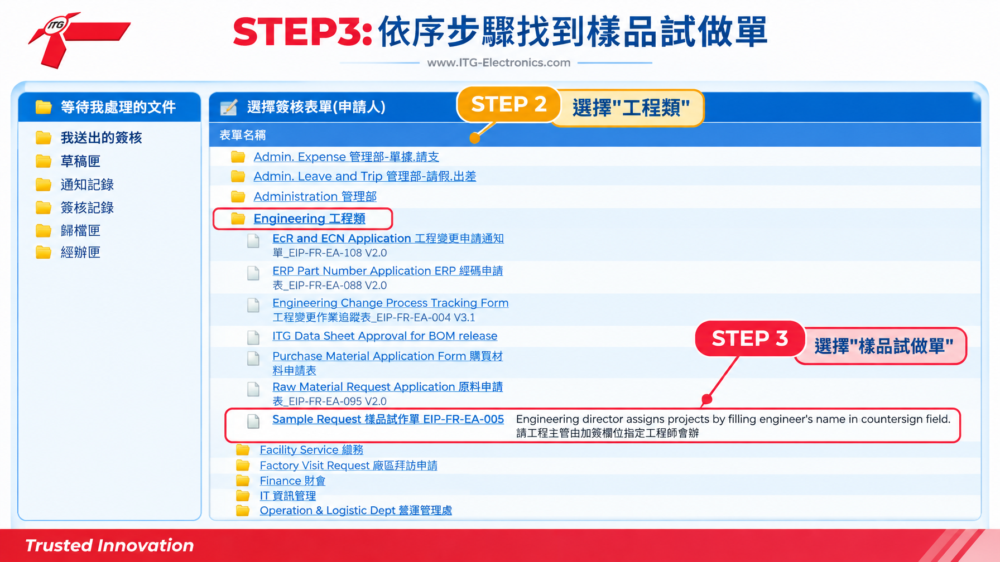

Page 5


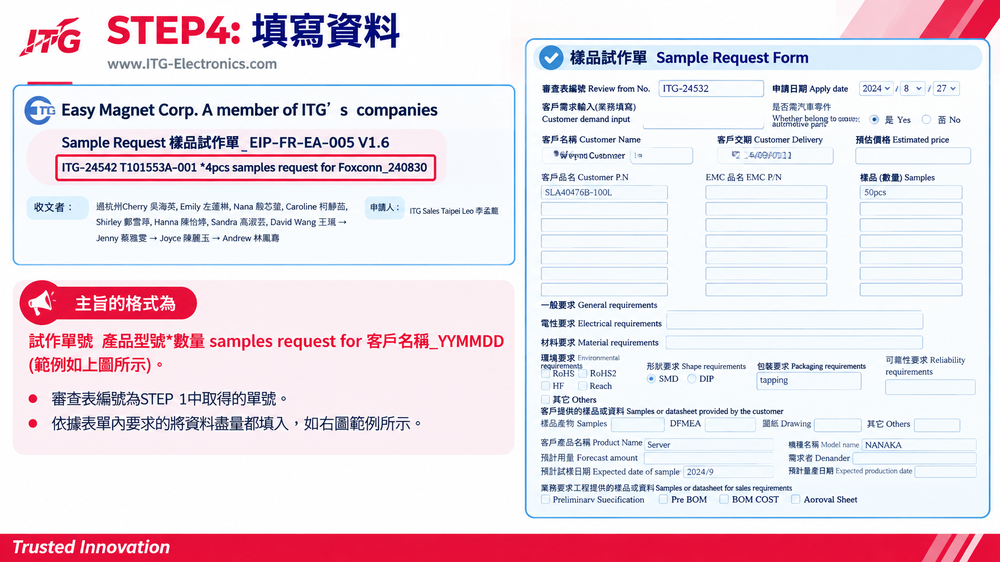

Page 6


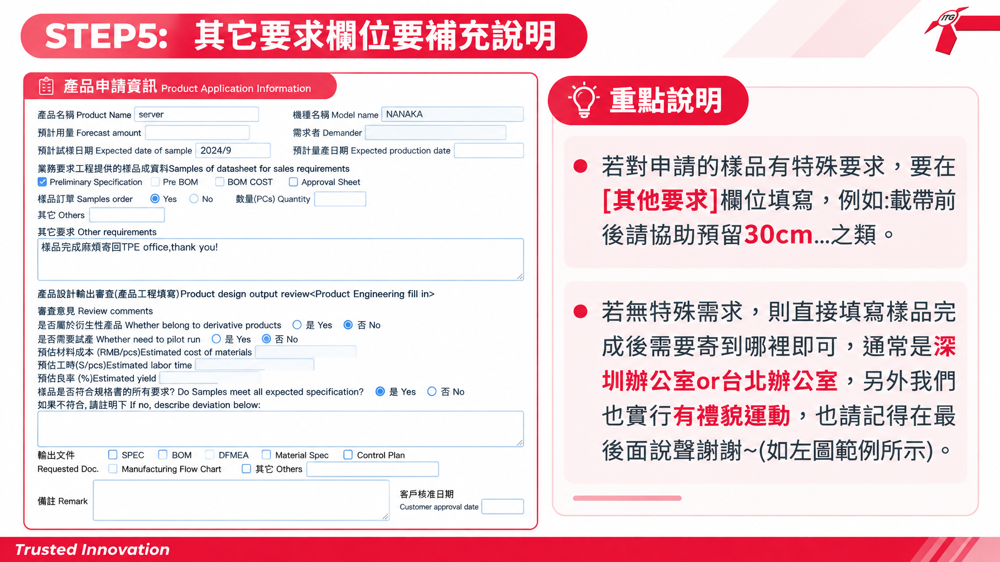

Page 7


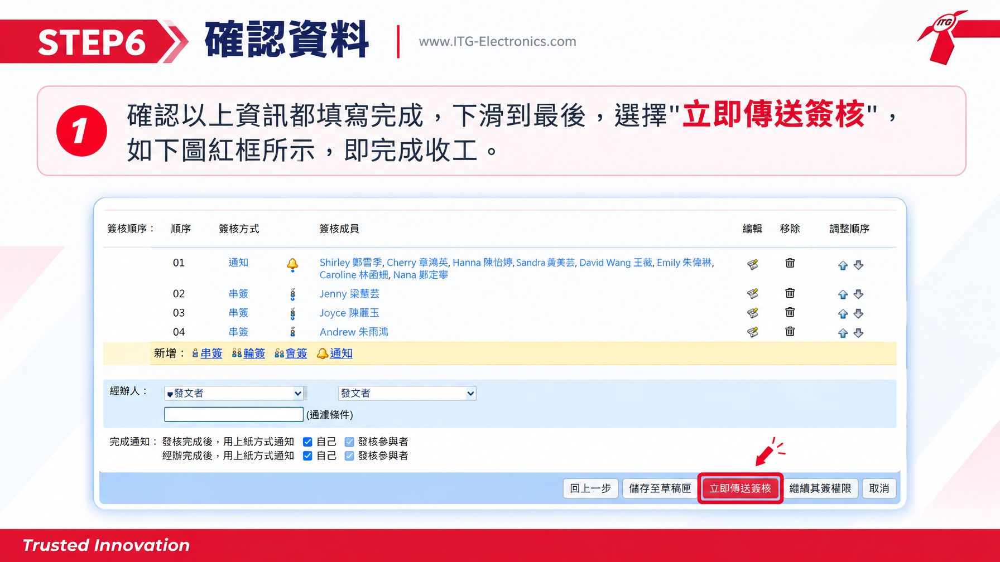

Page 8


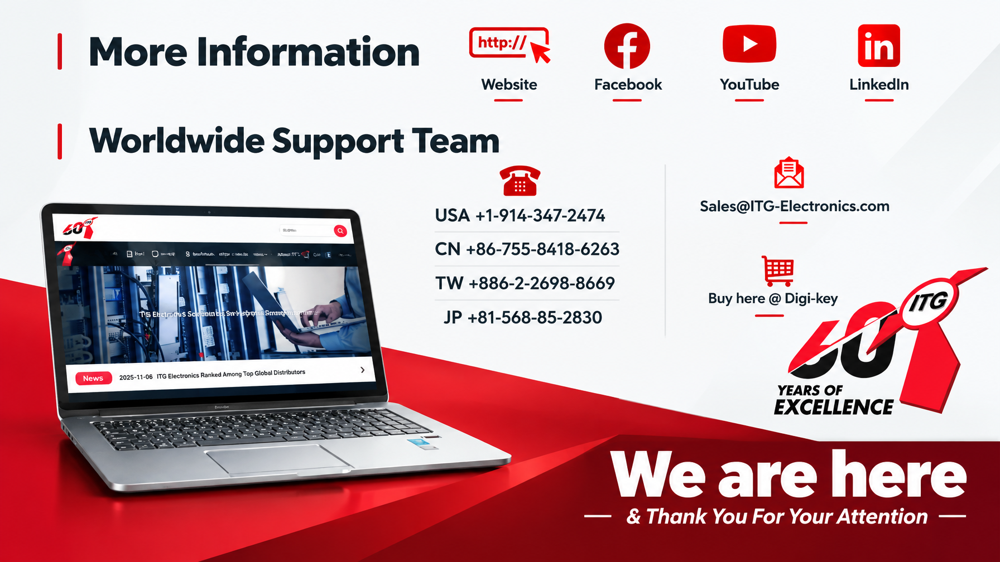

In [11]:
from IPython.display import display
from IPython.display import Image as JupyterImage

for i, image_bytes in enumerate(results):
    print(f"Page {i + 1}")
    display(JupyterImage(data=image_bytes))

Page 1


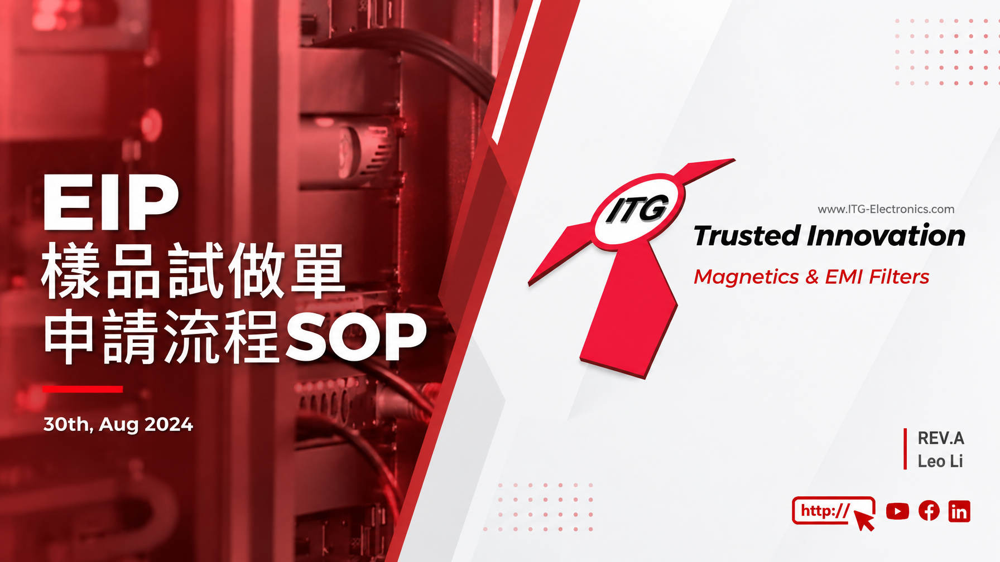

Page 2


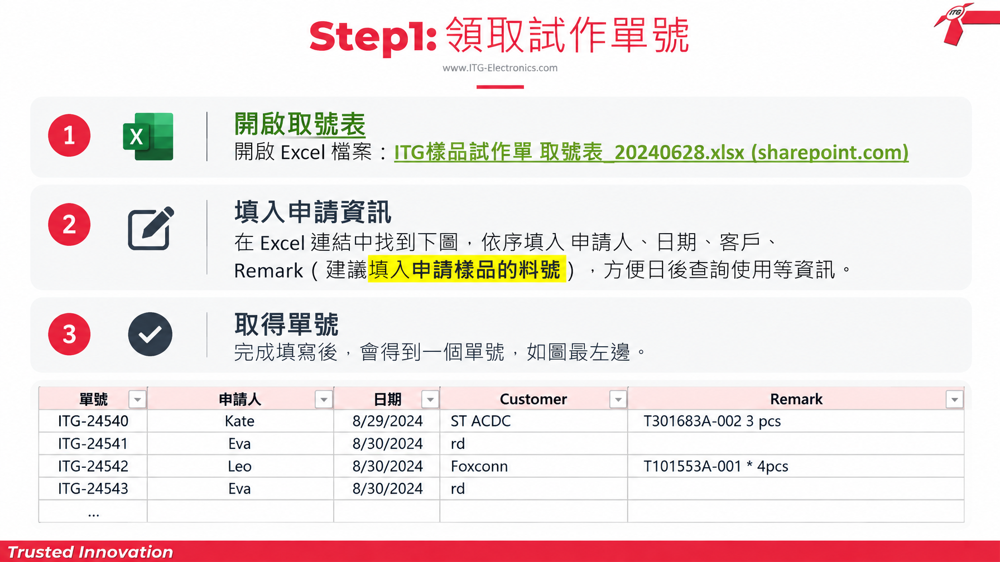

Page 3


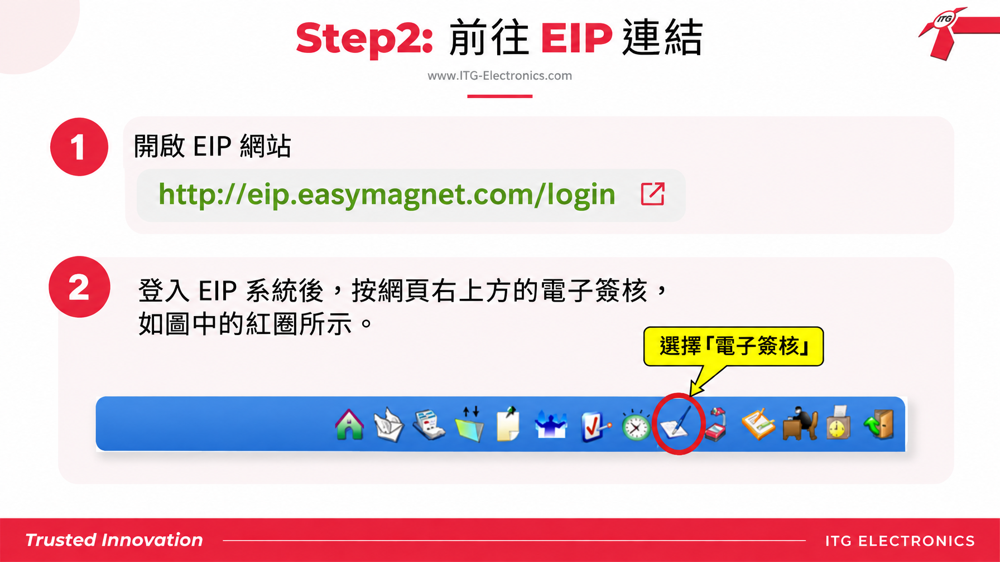

Page 4


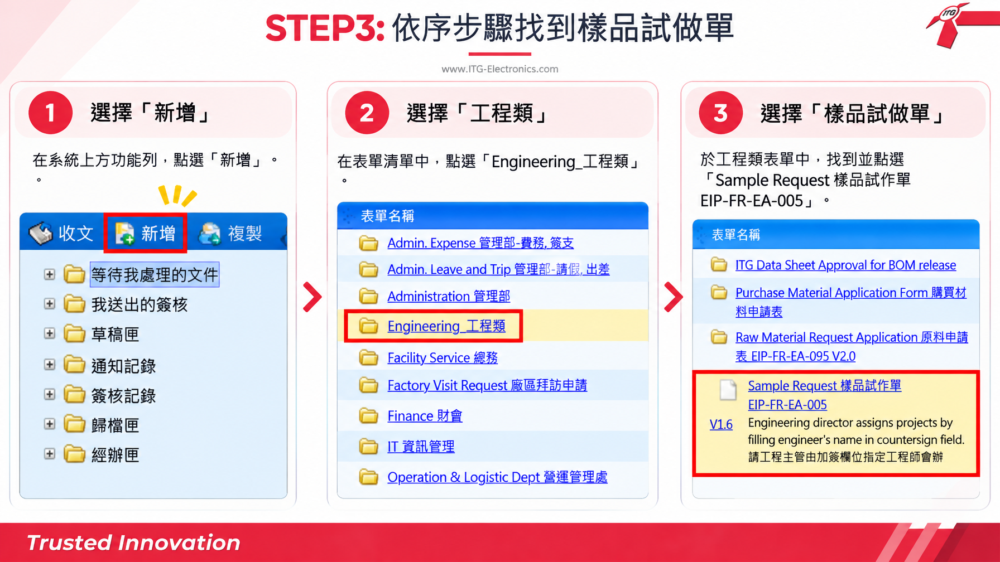

Page 5


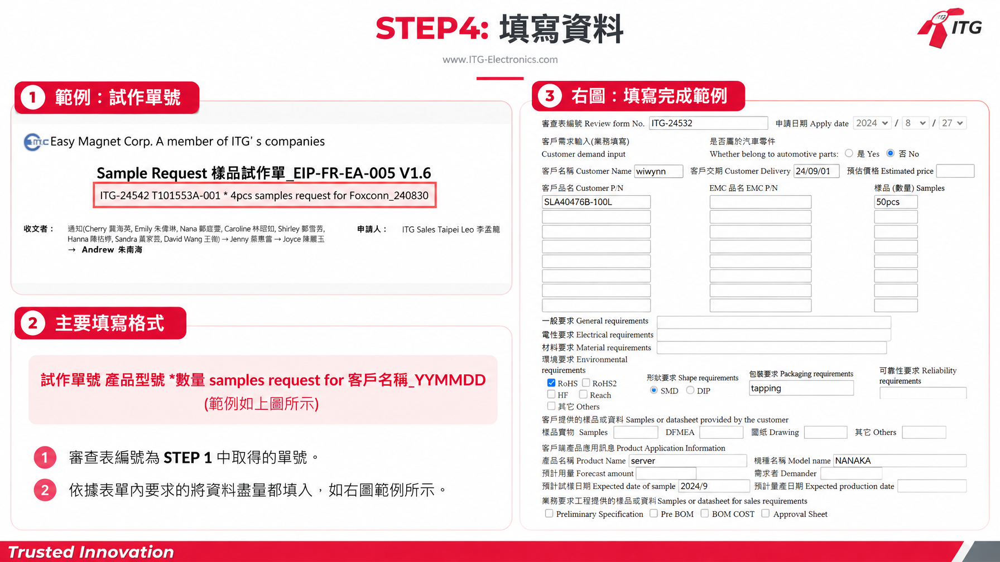

Page 6


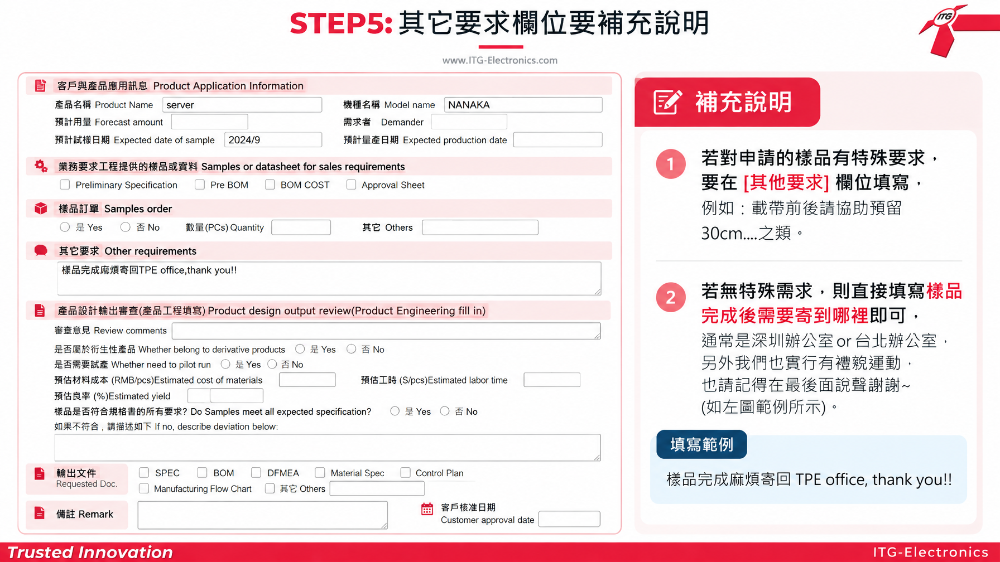

Page 7


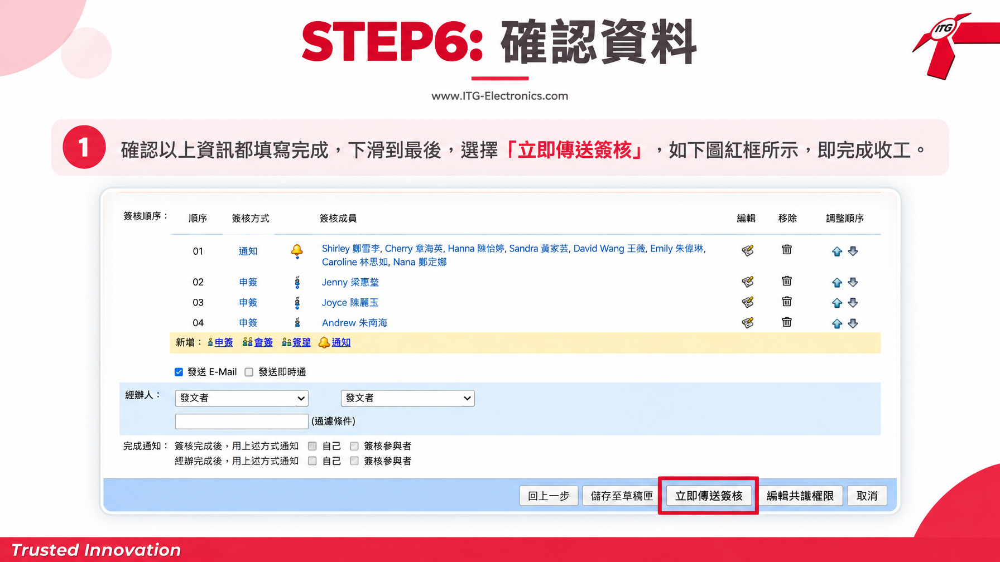

Page 8


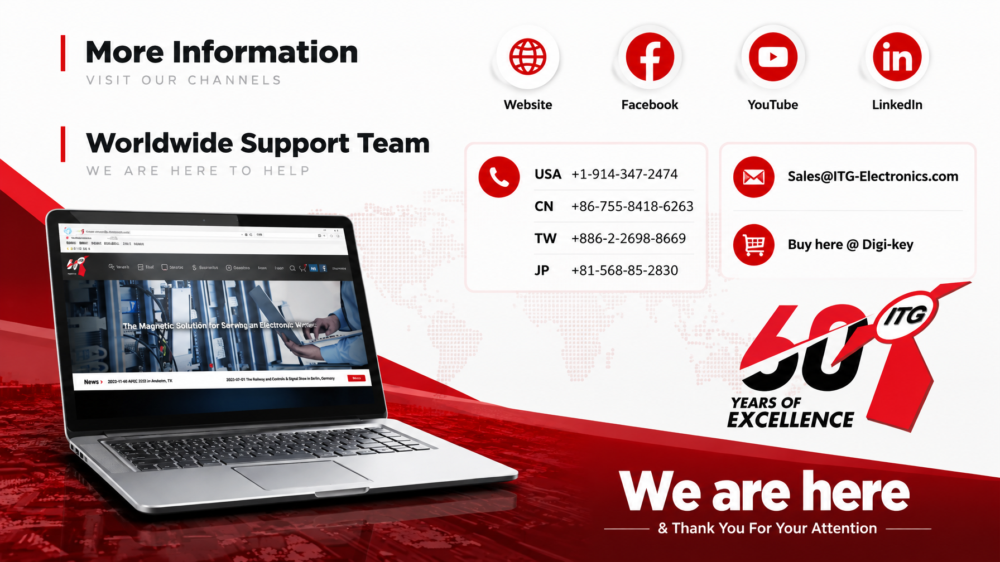

In [14]:
from IPython.display import display
from IPython.display import Image as JupyterImage

for i, image_bytes in enumerate(results):
    print(f"Page {i + 1}")
    display(JupyterImage(data=image_bytes))